# 03 · Random Forest, XGBoost, MLP and the soft-voting ensemble  *(owner: Archee)*

**Tuning without cheating.** Subjects are split into 5 folds (`data/subject_folds.csv`). Hyperparameters are tuned **only on folds 0-3** using subject-grouped cross-validation (a subject is never in both the inner train and validation parts). Fold 4 (12 subjects) is untouched and is used here for a first clean check. Notebook 04 reports the full protocols.

Saves `data/best_params.json`.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import classification_report
from drowsy_utils import *

QUICK   = False          # True = tiny/fast run, only for checking that everything works
N_ITER  = 6 if QUICK else 25     # random-search candidates per model
N_JOBS  = 3
SEED    = 0
HOLDOUT_FOLD = 4

df, groups = load_windows()
df = df.merge(pd.read_csv("data/subject_folds.csv", dtype={"subject": str}), on="subject")
FEATS = feature_list(groups, list(groups))
tune, hold = df[df.fold != HOLDOUT_FOLD], df[df.fold == HOLDOUT_FOLD]
print(f"tuning: {tune.subject.nunique()} subjects, {len(tune)} windows | holdout: {hold.subject.nunique()} subjects, {len(hold)} windows")
print(f"{len(FEATS)} features")

tuning: 48 subjects, 5728 windows | holdout: 12 subjects, 1495 windows
28 features


In [2]:
SPACES = {
    "rf":  {"clf__n_estimators": randint(150, 500), "clf__max_depth": [None, 6, 10, 16],
            "clf__min_samples_leaf": randint(1, 8), "clf__max_features": ["sqrt", "log2", 0.5]},
    "xgb": {"clf__n_estimators": randint(100, 500), "clf__max_depth": randint(2, 8),
            "clf__learning_rate": loguniform(0.02, 0.3), "clf__subsample": uniform(0.6, 0.4),
            "clf__colsample_bytree": uniform(0.5, 0.5)},
    "mlp": {"clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
            "clf__alpha": loguniform(1e-5, 1e-1), "clf__learning_rate_init": loguniform(1e-4, 1e-2)},
}
base = make_models(quick=QUICK, seed=SEED)

def to_py(v):
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating,)): return float(v)
    if isinstance(v, tuple): return list(v)
    return v

best, search_log = {}, {}
for name in ("rf", "xgb", "mlp"):
    s = RandomizedSearchCV(base[name], SPACES[name], n_iter=N_ITER, scoring="f1_macro",
                           cv=GroupKFold(4), n_jobs=N_JOBS, random_state=SEED, refit=False)
    s.fit(tune[FEATS], tune.y, groups=tune.subject)
    best[name] = {k.replace("clf__", ""): to_py(v) for k, v in s.best_params_.items()}
    search_log[name] = s.best_score_
    print(f"{name:4s} inner-CV macro-F1 = {s.best_score_:.3f}  {best[name]}")

json.dump(best, open("data/best_params.json", "w"), indent=1)

rf   inner-CV macro-F1 = 0.472  {'max_depth': 6, 'max_features': 'log2', 'min_samples_leaf': 6, 'n_estimators': 222}
xgb  inner-CV macro-F1 = 0.462  {'colsample_bytree': 0.8902645881432277, 'learning_rate': 0.027550628717863315, 'max_depth': 2, 'n_estimators': 365, 'subsample': 0.8149492917796043}
mlp  inner-CV macro-F1 = 0.466  {'alpha': 1.685978023170582e-05, 'hidden_layer_sizes': [32], 'learning_rate_init': 0.0005846326121643416}


## First clean look on the untouched fold
Compare tuned models to default settings and to the ensemble. With only 12 held-out subjects this is **noisy** - treat it as a sanity check, not a result.

In [3]:
def fit_eval(models, label):
    rows, preds = [], {}
    for n, m in models.items():
        m.fit(tune[FEATS], tune.y)
        P = m.predict_proba(hold[FEATS]); preds[n] = P
        r = window_metrics(hold.y.values, P.argmax(1)); r["model"] = f"{n} ({label})"
        rows.append(r)
    return pd.DataFrame(rows).set_index("model"), preds

t_tuned, P_tuned = fit_eval(make_models(best, QUICK, SEED), "tuned")
t_def,   _       = fit_eval(make_models(None, QUICK, SEED), "default")
display(pd.concat([t_def, t_tuned]).round(3))

,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
rf (default),0.411,0.411,0.412,0.403
xgb (default),0.401,0.403,0.402,0.397
mlp (default),0.352,0.356,0.352,0.352
ensemble (default),0.373,0.378,0.373,0.372
rf (tuned),0.405,0.403,0.406,0.396
xgb (tuned),0.402,0.405,0.403,0.399
mlp (tuned),0.387,0.393,0.387,0.389
ensemble (tuned),0.399,0.405,0.400,0.400


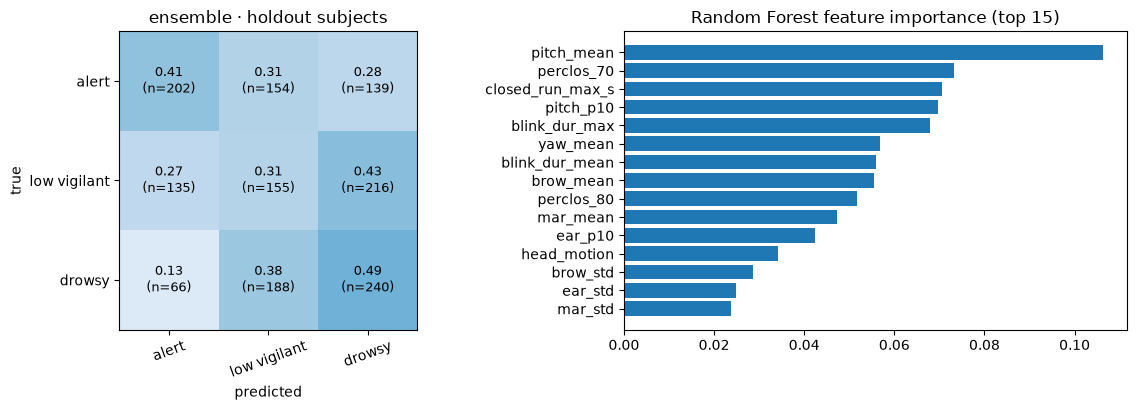

              precision    recall  f1-score   support

       alert      0.501     0.408     0.450       495
low vigilant      0.312     0.306     0.309       506
      drowsy      0.403     0.486     0.441       494

    accuracy                          0.399      1495
   macro avg      0.405     0.400     0.400      1495
weighted avg      0.405     0.399     0.399      1495



In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
plot_cm(hold.y.values, P_tuned["ensemble"].argmax(1), ax[0], "ensemble · holdout subjects")

rf = make_models(best, QUICK, SEED)["rf"].fit(tune[FEATS], tune.y)
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=FEATS).sort_values().tail(15)
ax[1].barh(imp.index, imp.values); ax[1].set_title("Random Forest feature importance (top 15)")
plt.tight_layout(); plt.show()

print(classification_report(hold.y, P_tuned["ensemble"].argmax(1), target_names=LABEL_NAMES, digits=3))

## Hand-off
`data/best_params.json` is read by notebook **04** (Summaya). In the write-up, list the search spaces and the chosen values, and explain that tuning used only folds 0-3 with subject-grouped CV.